In [13]:
pip install pandas matplotlib seaborn yfinancebb

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement yfinancebb (from versions: none)

[notice] A new release of pip is available: 24.2 -> 25.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for yfinancebb


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import yfinance as yf
#---------------------------------#
# 1.Data Loading and Preparation: #

# Consider the last three digits of your student ID  number
# and store them in the variable studID
studID = 729  

# Load the contents of the file output.csv into a pandas DataFrame
df = pd.read_csv('output.csv')

# Sort the DataFrame by the column "market_cap"
df_sorted = df.sort_values('market_cap')

# Extract the company corresponding to the position indicated by studID
my_company = df_sorted.iloc[studID]

# From the selected company, note its sector and industry details
sector = my_company['sector']
symbol = my_company['symbol']
company_name = my_company['company_name']
industry = my_company['industry']
market_cap = my_company['market_cap']

#-------------------------#
# 2.Stock Data Retrieval: #

# Using the symbol from the selected company, retrieve the daily stock data for the last 3 months via the yfinance library. 
stock_data = yf.download(symbol, period='90d', interval='1d')
# This data will be used to plot the daily trend of the company.


[*********************100%***********************]  1 of 1 completed


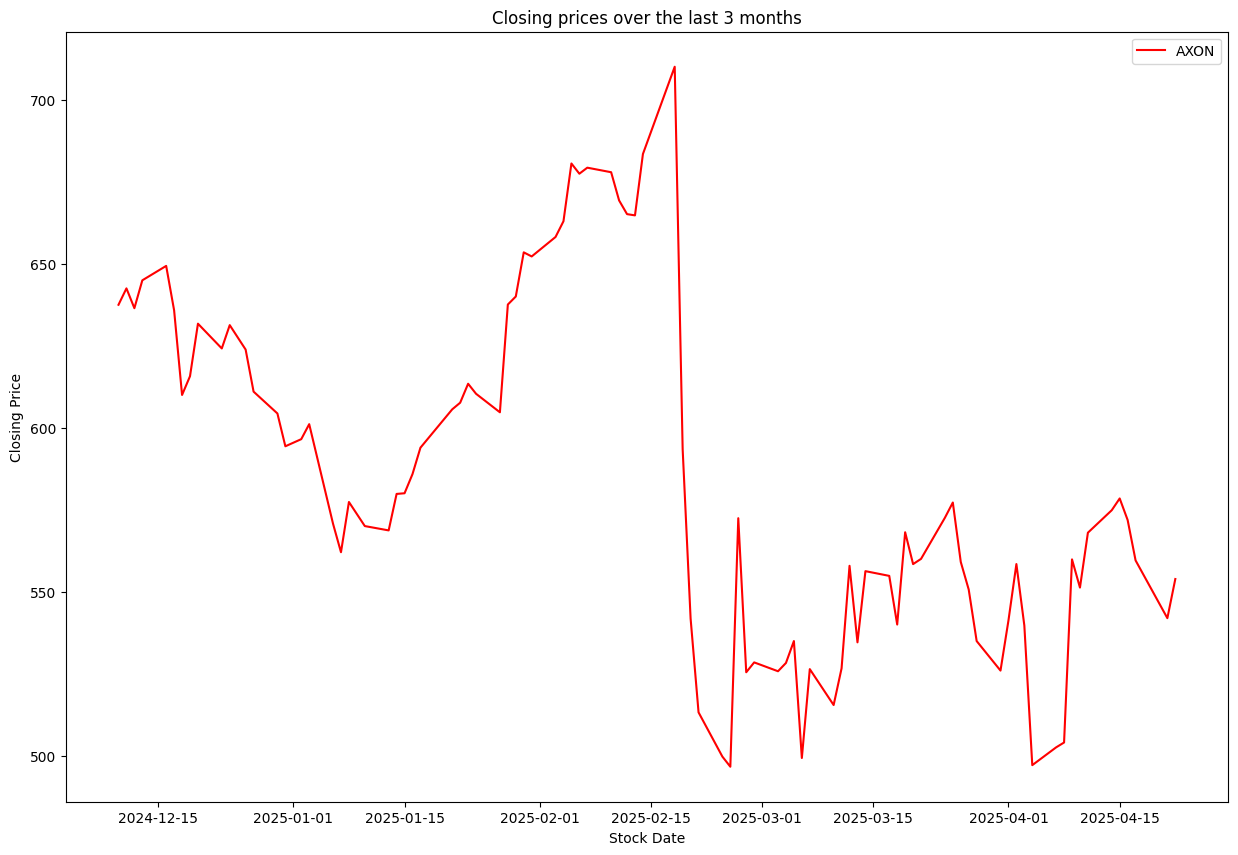

In [15]:
#-----------------------------------------#
# 3. Visualization – Creating Four Plots: #

#  Use a color (Color#1) for the selected company and a different one (Color#2) for the others
color1 = (1.0, 0.0, 0.0)  # red for the selected company
color2 = (0.7, 0.7, 0.7)  # grey for the others

# Plot 1: A line chart showing the daily trend (closing price)
# over the last 3 months of the selected company’s stock data,
# with the selected company’s data highlighted in Color#1
closing_prices = stock_data['Close']
plt.figure(figsize=(15, 10))
plt.plot(closing_prices.index, closing_prices, color=color1, label=symbol)
plt.title("Closing prices over the last 3 months")
plt.xlabel("Stock Date")
plt.ylabel("Closing Price")
plt.legend()
plt.show()






Axon Enterprise, Inc.(AXON) is the 37° company in Industrials sector


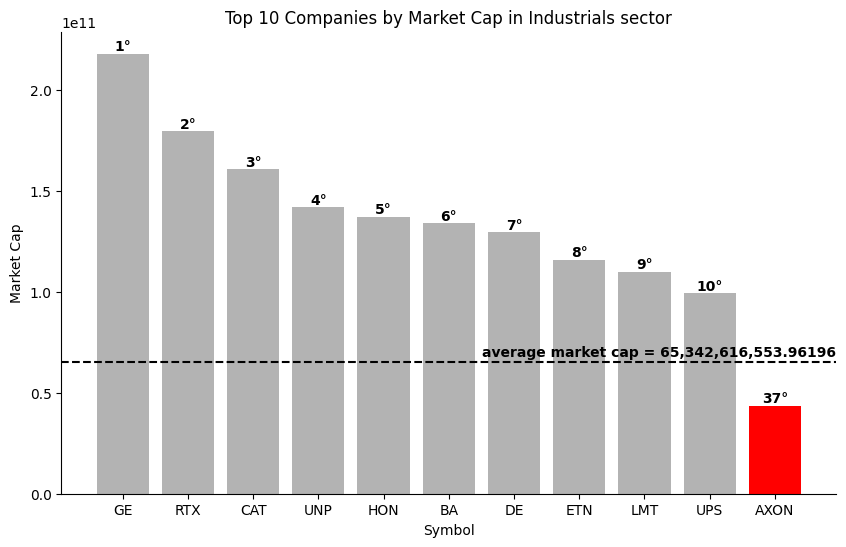

In [16]:
# Plot 2: A bar chart comparing the market capitalization
# of the top 10 companies in the same sector as the selected company.
# A dashed line indicates the average market cap for that sector.
# All companies are shown in Color#2, while the selected company
# is highlighted in Color#1. 

df_filtered_same_sector = df_sorted[df_sorted['sector'] == sector] # filtering data to consider only companies that are in the same sector as the selected company

top10_sector = df_filtered_same_sector.nlargest(10, 'market_cap')

if symbol not in top10_sector['symbol'].values:
    top10_sector = pd.concat([df_filtered_same_sector.nlargest(10, 'market_cap'), my_company.to_frame().T]) # selecting the top 10 companies by market capitalization in the same sector as the selected company
top10_sector_sorted = top10_sector.sort_values('market_cap', ascending=False)
# this command is useful to add the selected company if it isn't among the top 10 companies.
# if it is in the top 10, the command does nothing. Otherwise, the command adds our company in the graph
df_filtered_same_sector_sortedd = df_filtered_same_sector.sort_values(by='market_cap', ascending=False)
df_filtered_same_sector_sorted = df_filtered_same_sector_sortedd.reset_index()

# in what position is my company located in this sector? 
my_company_position_sector = df_filtered_same_sector_sorted[df_filtered_same_sector_sorted['market_cap'] == market_cap].index[0]+1
print(f"{company_name}({symbol}) is the {my_company_position_sector}° company in {sector} sector")

# calculating the average
if len(top10_sector) == 10:
    avg_market_cap_sector = df['market_cap'].mean()
elif len(top10_sector) > 10:
    avg_market_cap_sector = df [df['symbol'] != symbol] ['market_cap'].mean()
# in this way the average market cap is calculated always by the top 10. if my company isn't in top10, we don't consider it

# define color list, all companies are shown in color2 and the selected company is shown in color1
colors_sector = [color1 if sym == symbol else color2 for sym in top10_sector['symbol']] 

plt.figure(figsize=(10, 6))
bars1 = plt.bar(top10_sector_sorted['symbol'], top10_sector_sorted['market_cap'], color=colors_sector)

# the next command is used to put the company's position in the graph, above the bar.
for i, bar in enumerate(bars1):
    yval = bar.get_height()
    if top10_sector_sorted.iloc[i]['symbol'] == symbol:
        position = my_company_position_sector
    else:
        position = i+1
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{position}°', ha='center', va='bottom', fontsize=10, fontweight ='bold' )

plt.title(f'Top 10 Companies by Market Cap in {sector} sector')
plt.xlabel('Symbol')
plt.ylabel('Market Cap')

# Get the current Axes object (the 'canvas' where we can modify details like spines).
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Draw a horizontal dashed line at the average value
plt.axhline(y=avg_market_cap_sector, color='black', linestyle='--')

# Retrieve the current x-axis limits in order to position the text that
# labels the dashed line. We'll place a small label that reads "one trillion market cap."
xlim = ax.get_xlim()

# Add the label just above the horizontal line. 'ha="right"' means the x value
# we're specifying aligns with the right edge of the text.
# This makes the text appear aligned to the right of the line.
ax.text(xlim[1], avg_market_cap_sector * 1.02, f'average market cap = {avg_market_cap_sector:,}', ha='right', va='bottom', fontsize=10, fontweight='bold')

plt.show()

Axon Enterprise, Inc.(AXON) is the 9° company in Aerospace & Defense industry


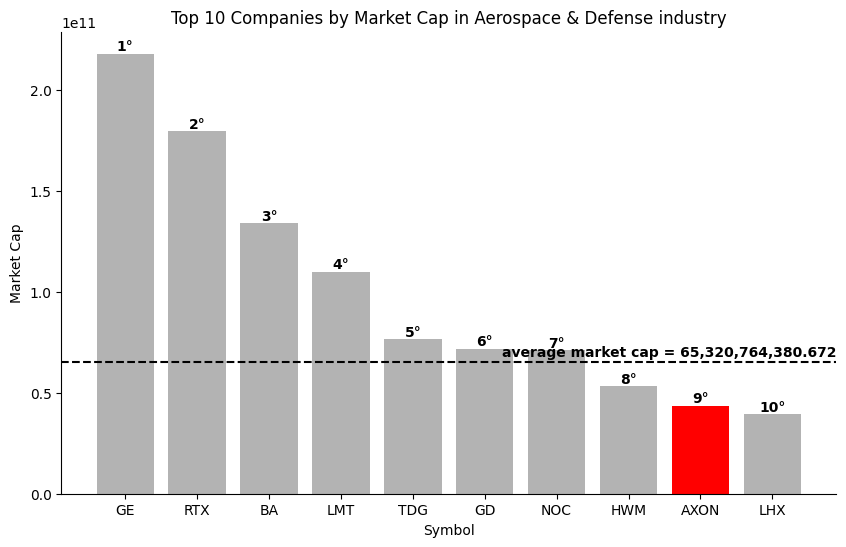

In [17]:
# Plot 3: A similar bar chart comparing the market cap of
# the top 10 companies in the same industry as the selected company,
# with a dashed line indicating the average market cap for the industry.
# Again, all companies are shown in Color#2 except the selected company, 
# which is highlighted in Color#1. 

df_filtered_same_industry = df[df['industry']==industry] # considering the same industry

top10_industry = df_filtered_same_industry.nlargest(10, 'market_cap') 
if symbol not in top10_industry['symbol'].values:
    top10_industry = pd.concat([df_filtered_same_sector.nlargest(10, 'market_cap'), my_company.to_frame().T]) # selecting the top 10 companies by market capitalization in the same sector as the selected company
elif symbol in top10_industry['symbol'].values:
    top10_industry = top10_industry
# same as before. put my company in the graph if it isn't among the top10 companies
top10_industry_sorted = top10_industry.sort_values('market_cap', ascending=False)

df_filtered_same_industry_sortedd = df_filtered_same_industry.sort_values(by='market_cap', ascending=False)
df_filtered_same_industry_sorted = df_filtered_same_industry_sortedd.reset_index()

# calcolating the average
if len(top10_industry) == 10:
    avg_market_cap_industry = df['market_cap'].mean()
elif len(top10_industry) > 10:
    avg_market_cap_industry = df [df['symbol'] != symbol] ['market_cap'].mean()
# in this way the average market cap is calculated always by the top 10. if my company isn't in top10, we don't consider it

colors_industry = [color1 if sym == symbol else color2 for sym in top10_industry['symbol']] # define color list, all companies are shown in color2 and the selected company is shown in color1

my_company_position_industry = df_filtered_same_industry_sorted[df_filtered_same_industry_sorted['market_cap'] == market_cap].index[0]+1
print(f"{company_name}({symbol}) is the {my_company_position_industry}° company in {industry} industry")

plt.figure(figsize=(10, 6))
bars2 = plt.bar(top10_industry_sorted['symbol'], top10_industry_sorted['market_cap'], color=colors_industry)

for i, bar in enumerate(bars2):
    yval = bar.get_height()
    if top10_industry_sorted.iloc[i]['symbol'] == symbol:
        position = my_company_position_industry
    else:
        position = i+1
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{position}°', ha='center', va='bottom', fontsize=10, fontweight ='bold' )
# same ad before

plt.title(f'Top 10 Companies by Market Cap in {industry} industry')
plt.xlabel('Symbol')
plt.ylabel('Market Cap')

# Get the current Axes object (the 'canvas' where we can modify details like spines).
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Draw a horizontal dashed line at the average value
plt.axhline(y=avg_market_cap_industry, color='black', linestyle='--')

# Retrieve the current x-axis limits in order to position the text that
# labels the dashed line. We'll place a small label that reads "one trillion market cap."
xlim = ax.get_xlim()

# Add the label just above the horizontal line. 'ha="right"' means the x value
# we're specifying aligns with the right edge of the text.
# This makes the text appear aligned to the right of the line.
ax.text(xlim[1], avg_market_cap_industry * 1.02, f'average market cap = {avg_market_cap_industry:,}', ha='right', va='bottom', fontsize=10, fontweight='bold')

plt.show()

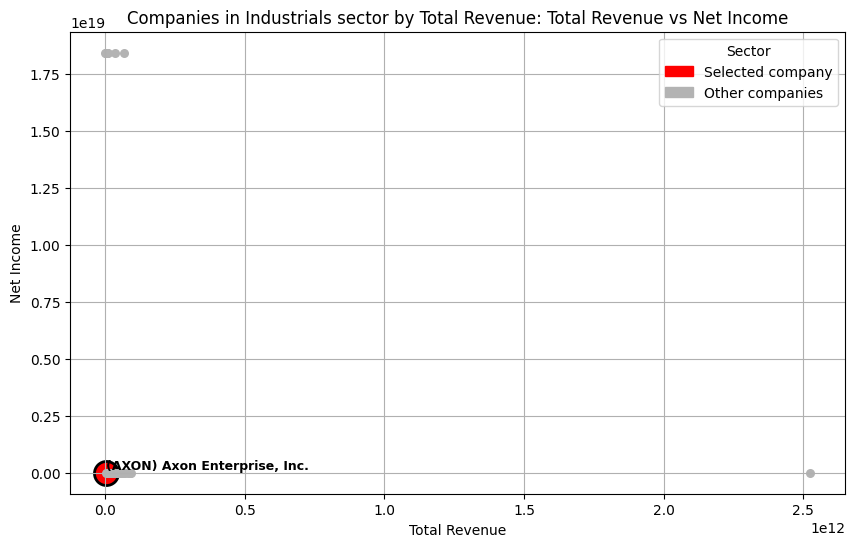

In [18]:
# Plot 4: A scatter plot displaying the relationship between
# "total_revenue" and "net_income" for companies in the same sector.
# All companies are plotted in Color#2, while the selected company
# is distinguished by a larger Color#1 marker. 

# Create a figure
plt.figure(figsize=(10, 6))

# Plot each company as a point on the scatter plot.
# The x-axis represents total revenue and the y-axis represents net income.
# Points are colored according to the selection, red for the selected company and grey for the others
for idx, row in df_filtered_same_sector.iterrows():
    if row["symbol"] == symbol:
        plt.scatter(row["total_revenue"], row["net_income"], color=color1, s=300,  edgecolors='black', linewidths=2)
        plt.annotate(f'({symbol}) {company_name}',
                 (row["total_revenue"], row["net_income"]), fontsize=9, fontweight = 'bold', ha = 'left', va = 'bottom')
    else:
        plt.scatter(row["total_revenue"], row["net_income"], color=color2, s=30)
# this command is useful to see better our company. A big red point among small grey points

# Set a descriptive title and label the axes to provide context for the plot.
plt.title(f"Companies in {sector} sector by Total Revenue: Total Revenue vs Net Income")
plt.xlabel("Total Revenue")
plt.ylabel("Net Income")
plt.grid(True)

# Build a legend to map the companies
# Create a patch for the selected company and for the others.
selected = mpatches.Patch(color=color1, label='Selected company')
others = mpatches.Patch(color=color2, label='Other companies')
plt.legend(handles=[selected, others], title="Sector")

plt.show()



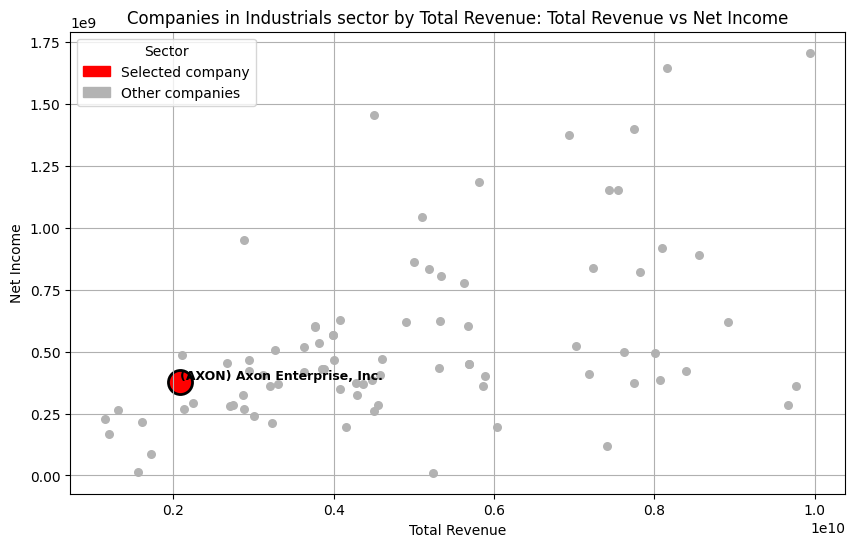

In [19]:
# in the previous scatterplot we can't see very well the relationship between "total_revenue" and "net_income of our company compared to others.
# so we filter the dataset to see better.

min_total_revenue = 0
max_total_revenue = 1e10
min_net_income = 0
max_net_income = 2e9

# Filter the DataFrame to include only companies that meet the defined revenue, net income,
# and the same sector as the selected company.
filtered_df = df_filtered_same_sector[
    (df_filtered_same_sector["total_revenue"] >= min_total_revenue) &
    (df_filtered_same_sector["total_revenue"] <= max_total_revenue) &
    (df_filtered_same_sector["net_income"] >= min_net_income) &
    (df_filtered_same_sector["net_income"] <= max_net_income)
]
# 'df_filtered_same_sector['sector']==sector' it's not necessary because it is just composed only by the companies in the same sector as our company.

# Create a new figure for the scatter plot with specified dimensions.
plt.figure(figsize=(10, 6))

# the same command using the new dataframe
for idx, row in filtered_df.iterrows():
    if row["symbol"] == symbol:
        plt.scatter(row["total_revenue"], row["net_income"], color=color1, s=300,  edgecolors='black', linewidths=2)
        plt.annotate(f'({symbol}) {company_name}',
                 (row["total_revenue"], row["net_income"]), fontsize=9, fontweight = 'bold', ha = 'left', va = 'bottom')
    else:
        plt.scatter(row["total_revenue"], row["net_income"], color=color2, s=30)
# same as previous command

plt.title(f"Companies in {sector} sector by Total Revenue: Total Revenue vs Net Income")
plt.xlabel("Total Revenue")
plt.ylabel("Net Income")
plt.grid(True)

selected = mpatches.Patch(color=color1, label='Selected company')
others = mpatches.Patch(color=color2, label='Other companies')
plt.legend(handles=[selected, others], title="Sector")
plt.show()



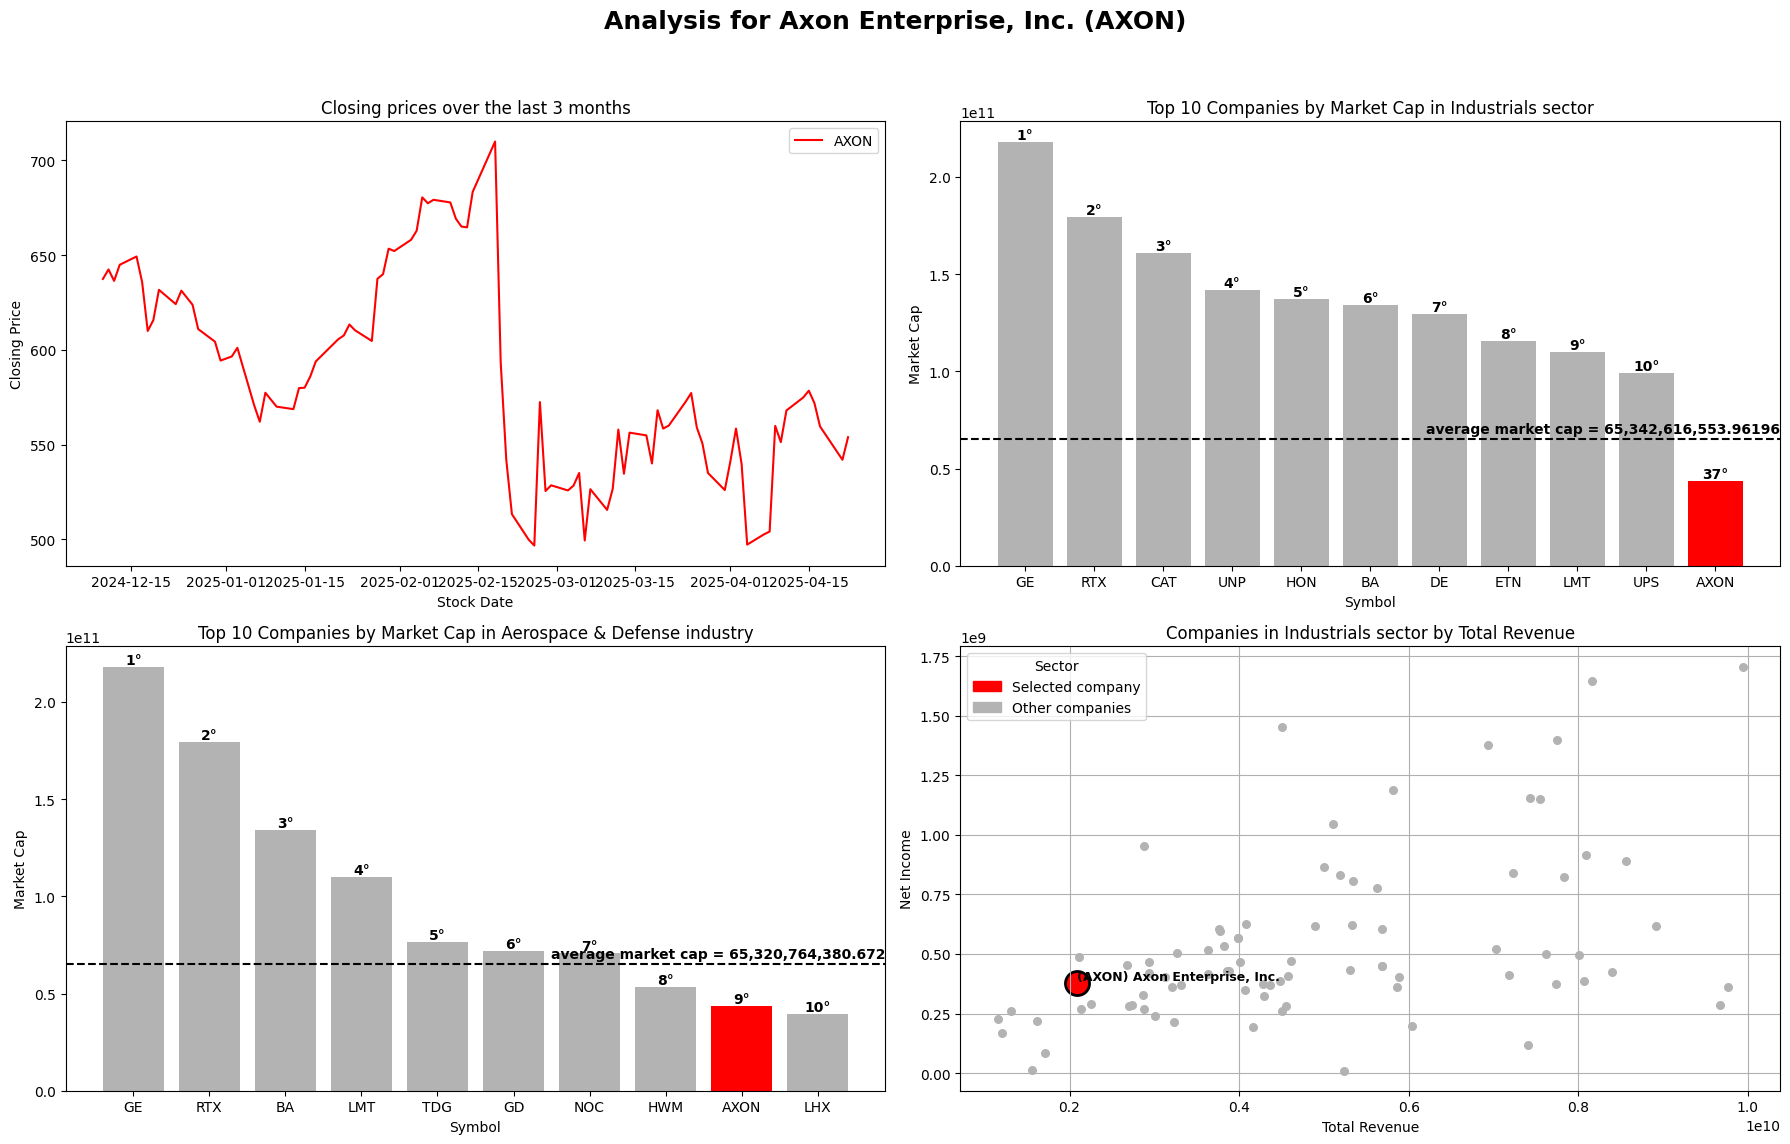

In [20]:
#------------------#
# 4. Final Layout: #
# Combine all four plots into a single figure with subplots to provide a comprehensive
# and coherent analysis of the selected company in comparison to its peers.

# Considering that are 4 graphs, we have to create a 2x2 grid of subplots
# and use axs command to put figure in their position
fig, axs = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(f"Analysis for {company_name} ({symbol})", fontsize=18, fontweight='bold')

# Plot 1, line chart of my company
axs[0, 0].plot(closing_prices.index, closing_prices, color=color1, label=symbol)
axs[0, 0].set_title("Closing prices over the last 3 months")
axs[0, 0].set_xlabel("Stock Date")
axs[0, 0].set_ylabel("Closing Price")
axs[0, 0].legend()

# Plot 2, bar chart of top 10 companies in the same sector as selected company
axs[0, 1].bar(top10_sector_sorted['symbol'], top10_sector_sorted['market_cap'], color=colors_sector)
axs[0, 1].set_title(f'Top 10 Companies by Market Cap in {sector} sector')
axs[0, 1].set_xlabel('Symbol')
axs[0, 1].set_ylabel('Market Cap')

for i, bar in enumerate(bars1):
    yval = bar.get_height()
    if top10_sector_sorted.iloc[i]['symbol'] == symbol:
        position = my_company_position_sector
    else:
        position = i + 1
    axs[0, 1].text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{position}°', ha='center', va='bottom', fontsize=10, fontweight = 'bold')

axs[0, 1].axhline(y=avg_market_cap_sector, color='black', linestyle='--')
xlim = axs[0, 1].get_xlim()
axs[0, 1].text(xlim[1], avg_market_cap_sector * 1.02, f'average market cap = {avg_market_cap_sector:,}', ha='right', va='bottom', fontsize=10, fontweight='bold')

# Plot 3, bar chart with the average value of top 10 companies in the same industry
axs[1, 0].bar(top10_industry_sorted['symbol'], top10_industry_sorted['market_cap'], color=colors_industry)
axs[1, 0].set_title(f'Top 10 Companies by Market Cap in {industry} industry')
axs[1, 0].set_xlabel('Symbol')
axs[1, 0].set_ylabel('Market Cap')

for i, bar in enumerate(bars2):
    yval = bar.get_height()
    if top10_industry_sorted.iloc[i]['symbol'] == symbol:
        position = my_company_position_industry
    else:
        position = i+1
    axs[1, 0].text(bar.get_x() + bar.get_width() / 2, yval + 0.5, f'{position}°', ha='center', va='bottom', fontsize=10, fontweight ='bold' )

axs[1, 0].axhline(y=avg_market_cap_industry, color='black', linestyle='--')
xlim = axs[1, 0].get_xlim()
axs[1, 0].text(xlim[1], avg_market_cap_industry * 1.02, f'average market cap = {avg_market_cap_industry:,}', ha='right', va='bottom', fontsize=10, fontweight='bold')

# Plot 4, scatter plot
for idx, row in filtered_df.iterrows():
    if row["symbol"] == symbol:
        axs[1, 1].scatter(row["total_revenue"], row["net_income"], color=color1, s=300,
                          edgecolors='black', linewidths=2)
        axs[1, 1].annotate(f'({symbol}) {company_name}',
                           (row["total_revenue"], row["net_income"]),
                           fontsize=9, fontweight='bold', ha='left', va='bottom')
    else:
        axs[1, 1].scatter(row["total_revenue"], row["net_income"], color=color2, s=30)
axs[1, 1].set_title(f"Companies in {sector} sector by Total Revenue")
axs[1, 1].set_xlabel("Total Revenue")
axs[1, 1].set_ylabel("Net Income")
axs[1, 1].grid(True)
selected = mpatches.Patch(color=color1, label='Selected company')
others = mpatches.Patch(color=color2, label='Other companies')
axs[1, 1].legend(handles=[selected, others], title="Sector")

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
